This notebook analyses the data previously published by [Thévenot et al. (2015)](https://doi.org/10.1021/acs.jproteome.5b00354) based on the work described in [Mendez et al. (2019)](https://doi.org/10.1007/s11306-019-1612-4).
The data was made "dirty" and then "cleaned" with different imputation strategies.

This notebook was written by Mauriz Lichtenstein

# 1. Import packages

In [1]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cross_decomposition import PLSRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, make_scorer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer

import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress only convergence warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 2. Load data

In [2]:
raw_url = 'https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS404.xlsx'

if not os.path.exists('../data/MTBLS404.xlsx'):
    # Download the file
    response = requests.get(raw_url)
    with open('../data/MTBLS404.xlsx', 'wb') as f:
        f.write(response.content)

DataTable = pd.read_excel('../data/MTBLS404.xlsx', sheet_name='Data')
PeakTable = pd.read_excel('../data/MTBLS404.xlsx', sheet_name='Peak')

print(DataTable.head())
print(PeakTable.head())

   Idx       SampleID  Class     Sex        M1       M2       M3         M4  \
0    1  HU_neg_011_b2      1    Male   33714.0   256102   256102  1120354.0   
1    2  HU_neg_014_b2      0  Female   99843.0   309401   309401  1398006.0   
2    3  HU_neg_015_b2      1    Male   88831.0   446367   446367  2525989.0   
3    4     HU_neg_017      1    Male    3193.0   202963   202963  1328899.0   
4    5     HU_neg_018      1    Male  148709.0  1141194  1141194  2213443.0   

        M5        M6  ...       M111      M112      M113       M114      M115  \
0  2410036  11549910  ...   521907.0  171324.0  127231.0  5112492.0  28514582   
1  6026857   5257922  ...  1833652.0   12438.0  979416.0  1895831.0  20498119   
2  9245374  17608775  ...   892482.0  176146.0  223930.0   627359.0  17310020   
3  3085203  10657431  ...   387400.0   84087.0  371298.0   571396.0   9114737   
4  7049050  13044183  ...   576816.0  451233.0  602941.0  3336582.0  19810476   

       M116    M117      M118       M1

/opt/homebrew/Caskroom/miniconda/base/envs/mlails/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/opt/homebrew/Caskroom/miniconda/base/envs/mlails/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


# 3. Make data dirty

In [3]:
# Extract PeakList
PeakList = PeakTable['Name']

# Count the number of missing values in each column
missing_values = DataTable[PeakList].isnull().sum()
print(f'The columns with missing values are: {missing_values[missing_values > 0].to_list()}')

The columns with missing values are: []


In [4]:
def make_mask(shape, strength, random_state=None):
    """Create a boolean mask with exactly strength% True values."""
    np.random.seed(random_state)
    n_total = shape[0] * shape[1]
    n_mask = int(strength * n_total)

    # Choose random flat indices to set to True
    mask_flat = np.zeros(n_total, dtype=bool)
    mask_flat[np.random.choice(n_total, size=n_mask, replace=False)] = True

    # Reshape to original DataFrame shape
    return mask_flat.reshape(shape)

def corrupt_remove_values(df, strength=0.1, random_state=None):
    dirty_df = df.copy()
    mask = make_mask(dirty_df.shape, strength, random_state)
    dirty_df[mask] = np.nan
    return dirty_df

def corrupt_change_values(df, strength=0.1, random_state=None):
    dirty_df = df.copy()
    mask = make_mask(dirty_df.shape, strength, random_state)
    noise = pd.DataFrame(
        np.random.normal(loc=0, scale=df.std(), size=df.shape),
        index=df.index,
        columns=df.columns
    )
    dirty_df = dirty_df + noise.where(mask, other=0)

    # Ensure all values remain positive (clip to minimum small value, e.g. 1e-6)
    dirty_df = dirty_df.clip(lower=1e-6)
    return dirty_df


X_clean = DataTable[PeakList].copy()

dirty_remove_10 = corrupt_remove_values(X_clean, strength=0.10, random_state=42)
dirty_remove_50 = corrupt_remove_values(X_clean, strength=0.50, random_state=42)

dirty_change_10 = corrupt_change_values(X_clean, strength=0.10, random_state=42)
dirty_change_50 = corrupt_change_values(X_clean, strength=0.50, random_state=42)

print("Total values in clean data:", X_clean.size)
print("NaNs in dirty_remove_10:", dirty_remove_10.isna().sum().sum())
print("NaNs in dirty_remove_50:", dirty_remove_50.isna().sum().sum())
print("Values changed in dirty_change_10:", ((X_clean - dirty_change_10).abs() > 1e-8).sum().sum())
print("Values changed in dirty_change_50:", ((X_clean - dirty_change_50).abs() > 1e-8).sum().sum())

Total values in clean data: 22080
NaNs in dirty_remove_10: 2208
NaNs in dirty_remove_50: 11040
Values changed in dirty_change_10: 2208
Values changed in dirty_change_50: 11040


# 4. Clean Data

In [5]:
def clean_knn(df, n_neighbors=3):
    imputer = KNNImputer(n_neighbors=n_neighbors)
    imputed = imputer.fit_transform(df)
    return pd.DataFrame(imputed, index=df.index, columns=df.columns)

def clean_iterative(df, random_state=42):
    imputer = IterativeImputer(random_state=random_state)

    # impute in log space to avoid negative values
    log_df = np.log(df)
    log_imputed = imputer.fit_transform(log_df)
    imputed = np.exp(log_imputed)
    return pd.DataFrame(imputed, index=df.index, columns=df.columns)

# Cleaned datasets using KNN
clean_knn_remove_10 = clean_knn(dirty_remove_10)
clean_knn_remove_50 = clean_knn(dirty_remove_50)

# Cleaned datasets using Iterative Regression
clean_iter_remove_10 = clean_iterative(dirty_remove_10)
clean_iter_remove_50 = clean_iterative(dirty_remove_50)

# Remove rows with missing values
clean_drop_remove_10 = dirty_remove_10.dropna()
clean_drop_remove_50 = dirty_remove_50.dropna()

print(clean_drop_remove_10.shape, clean_drop_remove_50.shape)

(0, 120) (0, 120)


dropping rows with NANs causes us to loose all the data!

# 5. Compare ML accuracy on imputed datasets
- No analysis on datasets with dropped NANs, because those datasets are empty

In [6]:
datasets = {
    'original': X_clean,
    'dirty_change_10': dirty_change_10,
    'dirty_change_50': dirty_change_50,
    'clean_knn_remove_10': clean_knn_remove_10,
    'clean_knn_remove_50': clean_knn_remove_50,
    'clean_iter_remove_10': clean_iter_remove_10,
    'clean_iter_remove_50': clean_iter_remove_50
}

In [7]:
# use the same hyperparameters as in PROJECT_1

def process_data(X, Y, test_size=1/3, random_state=40):
    XTrain, XTest, YTrain, YTest = train_test_split(X, Y, test_size=test_size, stratify=Y, random_state=random_state)
    preprocessor = Pipeline([
        ('log', FunctionTransformer(np.log, validate=True)),
        ('scale', StandardScaler())
    ])

    XTrain = preprocessor.fit_transform(XTrain)
    XTest = preprocessor.transform(XTest)
    return XTrain, XTest, YTrain, YTest

def evaluate_pls(X, Y):
    XTrain, XTest, YTrain, YTest = process_data(X, Y)

    model = PLSRegression(n_components=3)
    model.fit(XTrain, YTrain)
    ypred = model.predict(XTest).ravel()
    auc = roc_auc_score(YTest, ypred)
    return model, auc

def evaluate_ann(X, Y):
    XTrain, XTest, YTrain, YTest = process_data(X, Y)
    model = MLPClassifier(
            activation='logistic',
            solver='sgd',
            learning_rate_init=1,
            hidden_layer_sizes=(5,),
            momentum=0.5,
            learning_rate='constant',
            alpha=0.0,
            max_iter=400,
            random_state=42
            )
    model.fit(XTrain, YTrain)
    ypred = model.predict_proba(XTest)[:, 1]
    auc = roc_auc_score(YTest, ypred)
    return model, auc

In [8]:
Y = DataTable['Class'].values

results = []

for name, X in datasets.items():
    model_pls, auc_pls = evaluate_pls(X, Y)
    model_ann, auc_ann = evaluate_ann(X, Y)

    # Get the top 5 features from the PLS model
    pls_coeffs = model_pls.coef_.ravel()  # shape (n_features,)
    pls_top_idx = np.argsort(np.abs(pls_coeffs))[::-1][:5]
    pls_top_features = [(PeakList[i], PeakTable['Label'][i], pls_coeffs[i]) for i in pls_top_idx]

    # Get the top 5 features from the ANN model
    input_weights = model_ann.coefs_[0]      # shape: (n_features, n_hidden)
    output_weights = model_ann.coefs_[1]     # shape: (n_hidden,)
    importance_scores = np.abs(input_weights @ output_weights)  # shape: (n_features,)
    ann_top_idx = np.argsort(importance_scores, axis=0)[::-1][:5].flatten()
    ann_top_features = [(PeakList[i], PeakTable['Label'][i], importance_scores[i][0]) for i in ann_top_idx]

    results.append({
        'Dataset': name,
        'AUC_PLS': round(auc_pls, 3),
        'AUC_ANN': round(auc_ann, 3),
        'Samples': len(X),
        'pls_features': pls_top_features,
        'ann_features': ann_top_features
    })

/var/folders/sl/71vwpb6x7qj424_c15qnpdp80000gn/T/ipykernel_14104/1140310394.py:5: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.barplot(


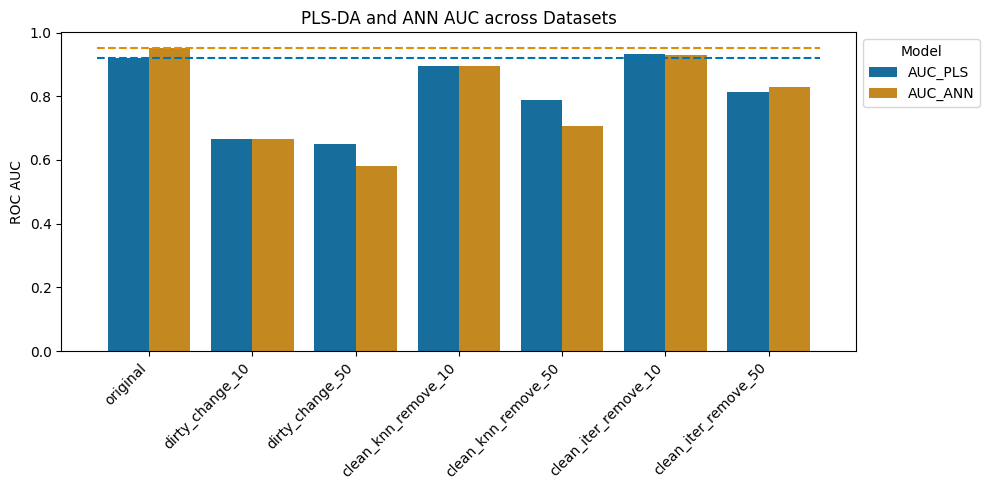

In [17]:
results_df = pd.DataFrame(results)
palette = sns.color_palette("colorblind")

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df.melt(id_vars='Dataset', value_vars=['AUC_PLS', 'AUC_ANN']),
    x='Dataset', 
    y='value', 
    hue='variable',
    palette=palette,
    )
plt.hlines(y=results_df['AUC_PLS'].iloc[0], xmin=-0.5, xmax=6.5, color=palette[0], linestyle='--')
plt.hlines(y=results_df['AUC_ANN'].iloc[0], xmin=-0.5, xmax=6.5, color=palette[1], linestyle='--')

plt.xticks(rotation=45, ha='right')
plt.ylabel("ROC AUC")
plt.xlabel("")
plt.title("PLS-DA and ANN AUC across Datasets")
plt.legend(title='Model', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig('../report/barplot_auc.png', dpi=300)
plt.show()

In [10]:
import pandas as pd

# Build a comparative table from the results list
table_rows = []

for res in results:
    dataset = res['Dataset']
    for i in range(5):
        pls_name, pls_label, pls_weight = res['pls_features'][i]
        ann_name, ann_label, ann_score = res['ann_features'][i]
        table_rows.append({
            'Dataset': dataset,
            'Rank': i + 1,
            'PLS Label': pls_label,
            'ANN Label': ann_label,
        })

# Convert to DataFrame
df_features = pd.DataFrame(table_rows)

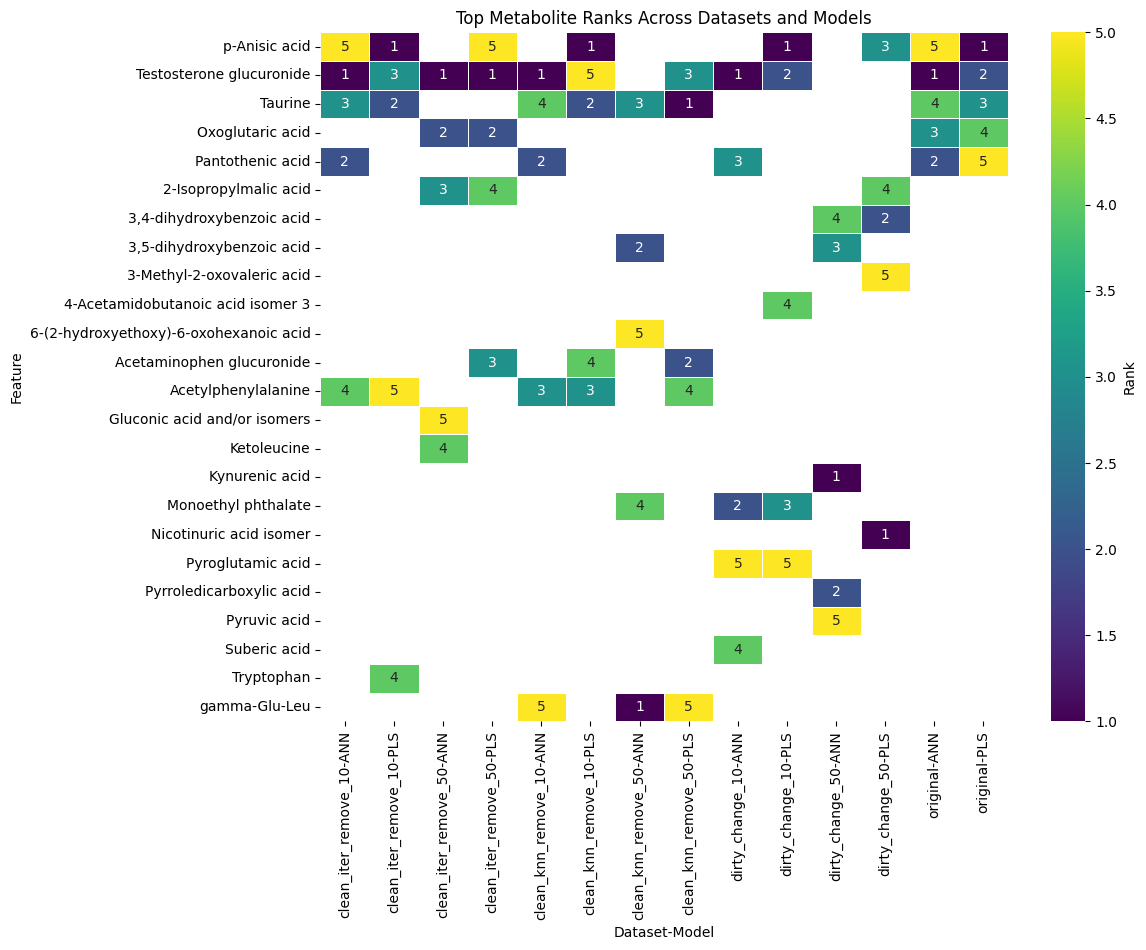

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Combine PLS and ANN features into long format for heatmap
rank_data = []

# Extract dataset order from results
dataset_order = [res['Dataset'] for res in results]

# Extract top 5 PLS metabolites from 'original' dataset
original_pls = next(res for res in results if res['Dataset'] == 'original')
top_pls_metabolites = [label for _, label, _ in original_pls['pls_features']]

for res in results:
    dataset = res['Dataset']
    for i, (pls, ann) in enumerate(zip(res['pls_features'], res['ann_features'])):
        pls_name, pls_label, _ = pls
        ann_name, ann_label, _ = ann
        rank_data.append((dataset, 'PLS', pls_label, i + 1))
        rank_data.append((dataset, 'ANN', ann_label, i + 1))

# Create DataFrame
df_rank = pd.DataFrame(rank_data, columns=['Dataset', 'Model', 'Feature', 'Rank'])

# Pivot table: features as rows, dataset+model as columns
heatmap_df = df_rank.pivot_table(index='Feature', columns=['Dataset', 'Model'], values='Rank')

# Sort datasets in column index
heatmap_df = heatmap_df[[col for col in heatmap_df.columns if col[0] in dataset_order]]
# heatmap_df = heatmap_df.sort_index(axis=1, key=lambda idx: [dataset_order.index(i[0]) * 2 + (0 if i[1] == 'PLS' else 1) for i in idx])

# Sort features: top 5 from original PLS first, then the rest alphabetically
remaining_features = [f for f in heatmap_df.index if f not in top_pls_metabolites]
sorted_features = top_pls_metabolites + sorted(remaining_features)
heatmap_df = heatmap_df.loc[sorted_features]

# Plot heatmap
plt.figure(figsize=(12, len(heatmap_df) * 0.4))
sns.heatmap(heatmap_df, annot=True, cmap="viridis", cbar_kws={'label': 'Rank'}, linewidths=0.5)
plt.title("Top Metabolite Ranks Across Datasets and Models")
plt.tight_layout()

plt.savefig('../report/heatmap.png', dpi=300)
plt.show()

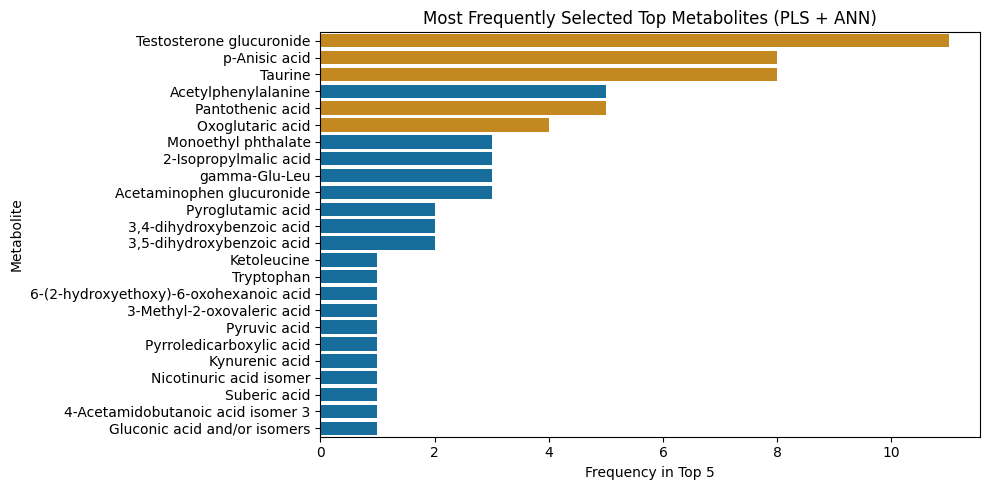

In [16]:
from collections import Counter

# Count how often each feature appears across all PLS + ANN results
feature_counts = Counter()

for res in results:
    feature_counts.update([f[1] for f in res['pls_features']])
    feature_counts.update([f[1] for f in res['ann_features']])

# Convert to DataFrame and sort
df_count = pd.DataFrame.from_dict(feature_counts, orient='index', columns=['Count'])
df_count = df_count.sort_values(by='Count', ascending=False)

df_count['Color'] = 0

for metabolite in df_rank[df_rank['Dataset'] == 'original']['Feature'].unique():
    df_count.loc[metabolite, 'Color'] = 1

palette = [sns.color_palette("colorblind")[0], sns.color_palette("colorblind")[1]]

# Plot
plt.figure(figsize=(10, 5))
sns.barplot(y=df_count.index, x=df_count['Count'], hue=df_count['Color'], palette = palette, legend=False)
plt.xlabel("Frequency in Top 5")
plt.ylabel("Metabolite")
plt.title("Most Frequently Selected Top Metabolites (PLS + ANN)")
plt.tight_layout()
plt.savefig('../report/barplot_features.png', dpi=300)

plt.show()